# Drone detection and Kalman-filter tracking

A camera watching the sky for small drones has two jobs. It has to find the drone in a single frame, and it has to follow the same drone from frame to frame when the detector misses it, mistakes a bird or a branch for it, or loses it behind a tree. In this assignment you do both on the DUT Anti-UAV benchmark ([Zhao et al., 2022](https://arxiv.org/abs/2205.10851)). You fine-tune a small single-stage detector on a subset of the benchmark's 5,200 training images, measure its average precision on the 2,200 test images, and then wrap it in a Kalman filter that tracks the drone through the benchmark's 20 videos.

The detector alone is a strong baseline. In each frame you can take its most confident box and call that the track. This assignment asks whether a Kalman filter with a constant-velocity motion model improves on that, by how much, and where it fails. You answer it with the one-pass evaluation used for single-object trackers: a success curve over box overlap thresholds and a precision curve over center-distance thresholds, scored on all 20 sequences.

The [Kalman filter lecture](/aiml-common/lectures/rse/kalman-filters) derives the predict and update equations you implement here.

The parts marked `TODO` are yours. Each one starts as a stub that runs, so the whole assignment runs top to bottom from the start and the scoring code reports a baseline: a detector fine-tuned for 3 epochs, and a tracker that reports the detector's most confident box in every frame. Your fine-tuned detector has to beat the 3-epoch detector. For the tracker, measure how it differs from the detector alone on every score and explain the difference. A filter that ties or loses on some scores is a valid result if you can say why. Finding the drone again after the track is lost is a firm requirement, set out in the section on losing and reacquiring the drone. Everything else, including the data loading and the scoring code, is given so that every submission is scored the same way. Do not change the scoring code.

In [37]:
%pip install -q ultralytics filterpy datasets

In [38]:
import io
import json
import pickle
import random
import shutil
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

## Settings

The defaults train on a random subset of 2,000 of the 5,200 training images and pick the best epoch on 400 validation images, which keeps training short. Keep them for the graded run. You may also raise `TRAIN_LIMIT` and `EPOCHS` and report both runs.

In [39]:
DATA = Path("dut-data")  # everything downloaded or derived goes here
RUNS = Path("runs")  # detector training output
TRAIN_LIMIT = 2000  # training images used; None uses all 5,200
VAL_LIMIT = 400  # validation images used to pick the best epoch
EPOCHS = 30  # fine-tuning epochs
IMGSZ = 640  # training input size in pixels
TRACK_IMGSZ = 640  # detector input size on the tracking frames; you may try 1280
DEVICE = 0 if torch.cuda.is_available() else "cpu"
AMP = torch.cuda.is_available() and torch.cuda.get_device_capability()[0] >= 7  # fp16 needs tensor cores
random.seed(0)
np.random.seed(0)
DATA.mkdir(exist_ok=True)
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

Tesla T4


## The detection data

The detection part of DUT Anti-UAV has 10,000 visible-light images split into 5,200 for training, 2,600 for validation and 2,200 for testing. They hold 10,109 labeled drones of a single class, `UAV`. Each image comes with a Pascal VOC annotation, one box per drone given by its corner coordinates `[xmin, ymin, xmax, ymax]` in pixels. Three training images contain no drone.

The drones are small. The median box is about 2% of the image width, so a drone in a 1920 pixel frame is roughly 40 pixels wide and shrinks to about 14 pixels when the frame is resized to the 640 pixel input of the detector. The images range from 240 to 5,616 pixels on the long side, so they are resized once, to at most 1,280 pixels, when they are converted to the detector's label format. The conversion writes one text line per box: the class index followed by the box center, width and height, each divided by the image size.

In [40]:
from datasets import Image as ImageFeature
from datasets import load_dataset

DETECTION = load_dataset("aegean-ai/dut-anti-uav", "detection")
DETECTION = DETECTION.cast_column("image", ImageFeature(decode=False))  # keep raw JPEG bytes
for split, rows in DETECTION.items():
    print(f"{split}: {len(rows)} images, {sum(len(o['bbox']) for o in rows['objects'])} boxes")

train: 5200 images, 5243 boxes
validation: 2600 images, 2621 boxes
test: 2200 images, 2245 boxes


In [41]:
def rows_to_yolo(rows, out_dir, split, limit=None, max_side=1280, seed=0, exclude=()):
    """Write a YOLO-format copy of one split of the Parquet detection set.

    rows is a datasets split with the image column left undecoded (raw JPEG bytes).
    Images whose image_id is in exclude are skipped before the subset is drawn. Each image is shrunk so its long side is at most max_side; YOLO labels are relative
    to the image size, so they do not change with the resize. Returns the image count.
    """
    out_dir = Path(out_dir)
    excluded = set(exclude)
    indices = [i for i, image_id in enumerate(rows["image_id"]) if image_id not in excluded]
    if limit is not None and limit < len(indices):
        indices = sorted(random.Random(seed).sample(indices, limit))
    img_out = out_dir / "images" / split
    lbl_out = out_dir / "labels" / split
    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)
    for row in rows.select(indices):
        width, height = row["width"], row["height"]
        image = Image.open(io.BytesIO(row["image"]["bytes"]))
        scale = max_side / max(image.size)
        if scale < 1:
            target = (round(image.size[0] * scale), round(image.size[1] * scale))
            image.draft("RGB", target)  # fast JPEG decode at reduced size
            image = image.convert("RGB").resize(target, Image.BILINEAR)
        else:
            image = image.convert("RGB")
        image.save(img_out / f"{row['image_id']}.jpg", quality=95)
        lines = []
        for x1, y1, x2, y2 in row["objects"]["bbox"]:  # Pascal VOC corners in pixels
            cx, cy = (x1 + x2) / 2 / width, (y1 + y2) / 2 / height
            w, h = (x2 - x1) / width, (y2 - y1) / height
            lines.append(f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")
        (lbl_out / f"{row['image_id']}.txt").write_text("\n".join(lines))
    return len(indices)

Some detection images are frames cut from the tracking videos you will score the tracker on. Matching every detection image against every tracking frame finds 517 of them, from 11 of the 20 videos: 285 in the training split, 139 in the validation split and 93 in the test split. A detector trained on those frames has already seen the exact scenes, and often the exact drone positions, that the tracker is later scored on. The training and validation frames are held out below, so the training subset is drawn from the remaining images. The test split stays complete, so its average precision is comparable with published results.

In [42]:
# Detection images that are frames of the 20 tracking videos (found by image matching).
TRACKING_FRAMES_TRAIN = """
    00263 00271 00398 00399 00403 00404 00869 00870 00871 00872 00873 00874 00885 00886
    00887 00888 00889 00890 00891 00892 00893 00894 00895 00896 00897 00898 00899 00900
    00901 00902 00903 00904 00905 00906 00907 00908 00909 00910 00944 00945 00946 00947
    00948 00949 00950 00951 00952 00953 00954 00955 00956 00957 00958 00959 00960 00961
    00962 00963 00964 00965 00966 00967 00968 00969 00970 00971 00972 00973 00974 00975
    00976 00977 00978 00979 00980 00981 00982 00983 00984 00985 00986 00987 00988 01239
    01240 01241 01242 01243 01244 01245 01246 01247 01248 01249 01250 02935 02936 02937
    02938 02939 02940 02941 02942 02943 02944 02945 02946 02947 02948 02949 02950 02951
    02952 02953 02954 02955 02956 02957 02958 02959 02960 02961 02962 02963 02964 02965
    02966 02967 02968 02969 02970 02971 02972 02973 02974 03138 03139 03140 03141 03142
    03143 03144 03145 03146 03147 03148 03149 03150 03151 03152 03153 03154 03155 03156
    03157 03158 03159 03160 03161 03162 03163 03164 03165 03166 03167 03168 03363 03364
    03365 03366 03367 03368 03369 03370 03371 03372 03373 03374 03375 03376 03377 03378
    03379 03380 03381 03382 03383 03384 03385 03386 03387 03844 03845 03846 03847 03848
    03849 03850 03851 03852 03853 03854 03855 03856 03857 03858 03859 03860 03861 03862
    03863 03864 03865 03866 03867 03868 03869 03870 03871 03872 03873 03874 03875 03876
    03877 03878 03879 03880 03881 03882 03883 03884 03917 03918 03919 03920 03921 03922
    03923 03924 03925 03926 03927 03928 03929 03930 03931 03932 03933 03934 03935 03936
    03937 03938 03939 03940 03941 03942 03943 03944 03945 03946 03947 03948 03949 03950
    03951 03952 03953 03954 03955 03956 03957 03958 03959 03960 03961 03962 03963 03964
    03965 03966 03967 03968 03969
""".split()
TRACKING_FRAMES_VAL = """
    00200 00202 00203 00436 00437 00444 00445 00446 00447 00448 00449 00450 00451 00452
    00453 00454 00455 00473 00474 00475 00476 00477 00478 00479 00480 00481 00482 00483
    00484 00485 00486 00487 00488 00489 00490 00491 00492 00493 00494 00495 00621 00622
    00623 00624 00625 01469 01470 01471 01472 01473 01474 01475 01476 01477 01478 01479
    01480 01481 01482 01483 01484 01485 01486 01487 01570 01571 01572 01573 01574 01575
    01576 01577 01578 01579 01580 01581 01582 01583 01584 01585 01683 01684 01685 01686
    01687 01688 01689 01690 01691 01692 01693 01694 01923 01924 01925 01926 01927 01928
    01929 01930 01931 01932 01933 01934 01935 01936 01937 01938 01939 01940 01941 01942
    01959 01960 01961 01962 01963 01964 01965 01966 01967 01968 01969 01970 01971 01972
    01973 01974 01975 01976 01977 01978 01979 01980 01981 01982 01983 01984 01985
""".split()
EXCLUDE = {"train": TRACKING_FRAMES_TRAIN, "validation": TRACKING_FRAMES_VAL, "test": []}
print(len(TRACKING_FRAMES_TRAIN), "training and", len(TRACKING_FRAMES_VAL), "validation images held out")

285 training and 139 validation images held out


In [43]:
YOLO_DIR = DATA / "yolo"
SETTINGS = {"train": TRAIN_LIMIT, "val": VAL_LIMIT, "exclude": {k: sorted(v) for k, v in EXCLUDE.items()}}
MARKER = YOLO_DIR / "settings.json"
if YOLO_DIR.exists() and (not MARKER.exists() or json.loads(MARKER.read_text()) != SETTINGS):
    shutil.rmtree(YOLO_DIR)  # settings changed or a conversion was cut off: convert again from scratch
if not YOLO_DIR.exists():
    t0 = time.time()
    for split, name, limit in (("train", "train", TRAIN_LIMIT), ("validation", "val", VAL_LIMIT),
                               ("test", "test", None)):
        n = rows_to_yolo(DETECTION[split], YOLO_DIR, name, limit=limit, exclude=EXCLUDE[split])
        print(f"{split}: {n} images")
    print(f"converted in {time.time() - t0:.0f} s")
    MARKER.write_text(json.dumps(SETTINGS))  # written last, so it marks a finished conversion
DATA_YAML = DATA / "dut.yaml"
DATA_YAML.write_text(f"path: {YOLO_DIR.resolve()}\ntrain: images/train\nval: images/val\n"
                     f"test: images/test\nnames:\n  0: UAV\n")

99

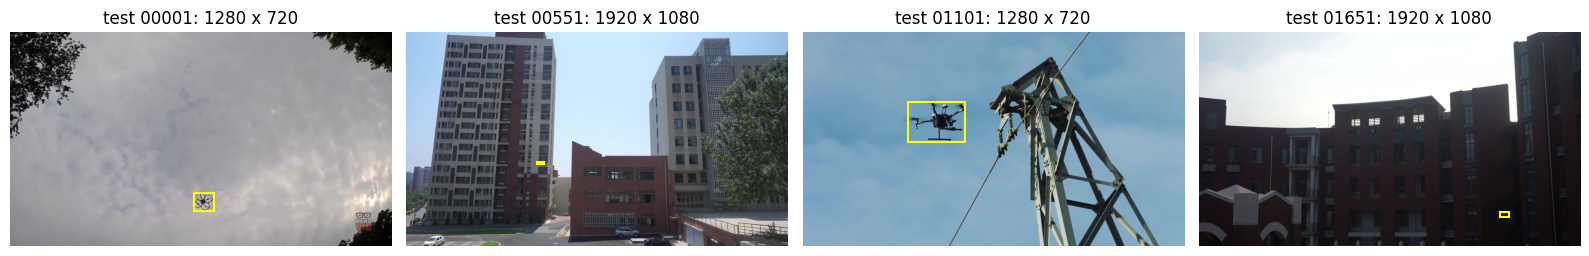

In [44]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, row in zip(axes, DETECTION["test"].select(range(0, 2200, 550))):
    ax.imshow(Image.open(io.BytesIO(row["image"]["bytes"])))
    for x1, y1, x2, y2 in row["objects"]["bbox"]:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="yellow", lw=1.5))
    ax.set_title(f"test {row['image_id']}: {row['width']} x {row['height']}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Fine-tuning the detector

You start from a detector pretrained on COCO, whose 80 classes do not include drones, and fine-tune it for the single `UAV` class. The pretrained backbone already encodes edges, textures and object parts, so a few thousand labeled images are enough to adapt the head and the upper layers. Use the nano-sized model of the YOLO11 family (`yolo11n.pt`, about 2.6 million parameters). It trains quickly and runs on every frame of the tracking videos in minutes.

Two settings matter for small targets. The input size sets how many pixels a drone covers after resizing, and the validation split decides which epoch's weights you keep. The training loop keeps the weights with the best validation score in `RUNS/detector/weights/best.pt`.

In [45]:
from ultralytics import YOLO

# Fine-tune the COCO-pretrained YOLO11n for the single UAV class with the settings above:
# EPOCHS (30) epochs on TRAIN_LIMIT (2,000) training images at IMGSZ (640) pixels; the epoch with the
# best validation score on VAL_LIMIT (400) images is kept as best.pt.
#   cos_lr        decays the learning rate smoothly to the last epoch instead of stepping it.
#   close_mosaic  switches mosaic augmentation off for the last 10 epochs, so the detector finishes on
#                 whole frames at their real scale; mosaic shrinks each tile, and these drones are tiny.
#   cache="ram"   keeps the decoded, resized images in memory (about 1.5 GB) so the GPU does not wait
#                 on JPEG decoding.
t0 = time.time()
model = YOLO("yolo11n.pt")
model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=16, workers=2,
            amp=AMP, seed=0, device=DEVICE, project=str(RUNS.resolve()), name="detector",
            exist_ok=True, plots=False, verbose=False, cos_lr=True, close_mosaic=10, cache="ram")
print(f"training took {(time.time() - t0) / 60:.1f} min")

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=dut-data/dut.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=detector, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, ov

## Detection accuracy on the test split

Average precision at an IoU threshold of 0.5 (mAP@0.5) counts a detection as correct when its box overlaps a labeled drone by at least half of their union, ranks all detections by confidence, and integrates precision over recall. With one class, the mean over classes is just that class's average precision. The stricter mAP@0.5:0.95 averages the same quantity over IoU thresholds from 0.5 to 0.95. Evaluating at a larger input size than the training size often helps small objects, because the drone covers more pixels.

In [46]:
detector = YOLO(RUNS / "detector" / "weights" / "best.pt")
det_results = {}
for size in (IMGSZ, 1280):
    metrics = detector.val(data=str(DATA_YAML), split="test", imgsz=size, batch=16, device=DEVICE,
                           plots=False, verbose=False, project=str(RUNS.resolve()), name=f"test_{size}",
                           exist_ok=True)
    det_results[size] = (metrics.box.map50, metrics.box.map)
    print(f"test split, input {size}: mAP@0.5 = {metrics.box.map50:.3f}, mAP@0.5:0.95 = {metrics.box.map:.3f}")

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 66.8±17.4 MB/s, size: 195.9 KB)
val: Scanning /content/dut-data/yolo/labels/test.cache... 2200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2200/2200 659.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 138/138 7.0it/s 19.7s
                   all       2200       2245      0.938      0.824       0.89      0.559
Speed: 0.7ms preprocess, 2.4ms inference, 0.0ms loss, 1.6ms postprocess per image
test split, input 640: mAP@0.5 = 0.890, mAP@0.5:0.95 = 0.559
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1872.8±801.1 MB/s, size: 147.4 

In [47]:
# The 3-epoch stub detector, scored by the unmodified notebook on the same 2,200 test images.
BASELINE_MAP50 = {640: 0.697, 1280: 0.746}
for size, (map50, map5095) in det_results.items():
    print(f"input {size:4d}: mAP@0.5 {map50:.3f} (3-epoch baseline {BASELINE_MAP50[size]:.3f}, "
          f"{map50 - BASELINE_MAP50[size]:+.3f}), mAP@0.5:0.95 {map5095:.3f}")

input  640: mAP@0.5 0.890 (3-epoch baseline 0.697, +0.193), mAP@0.5:0.95 0.559
input 1280: mAP@0.5 0.906 (3-epoch baseline 0.746, +0.160), mAP@0.5:0.95 0.586


## The tracking data

The tracking part of the benchmark has 20 videos, `video01` to `video20`, with 24,804 frames in total. Sequences run from 83 to 2,635 frames. Every frame comes with a ground-truth box `[x, y, w, h]`: the top-left corner, the width and the height of the drone's box in pixels. When the drone is out of view, the box reads `[-100, -100, -100, -100]`. That happens in 2,586 frames, all in 9 of the videos, and the loader below turns those boxes into `NaN`. The frames are written to disk once, one folder per video, with one ground-truth file per video holding one line per frame.

In [48]:
TRACK_ROOT = DATA / "track"
if not (TRACK_ROOT / "Anti-UAV-Tracking-V0GT").exists():
    tracking = load_dataset("aegean-ai/dut-anti-uav", "tracking", split="test")
    tracking = tracking.cast_column("image", ImageFeature(decode=False))  # keep raw JPEG bytes
    boxes = {}
    for row in tracking:  # rows are sorted by video, then frame
        frame_dir = TRACK_ROOT / "Anti-UAV-Tracking-V0" / row["video_id"]
        frame_dir.mkdir(parents=True, exist_ok=True)
        (frame_dir / f"{row['frame_index']:05d}.jpg").write_bytes(row["image"]["bytes"])
        boxes.setdefault(row["video_id"], []).append(row["bbox"])
    gt_dir = TRACK_ROOT / "Anti-UAV-Tracking-V0GT"
    gt_dir.mkdir()  # written last, so its presence marks a finished export
    for video_id, rows in boxes.items():
        np.savetxt(gt_dir / f"{video_id}_gt.txt", np.array(rows), fmt="%d")
SEQUENCES = [f"video{i:02d}" for i in range(1, 21)]

In [49]:
def load_sequence(track_root, name):
    """Frame paths, ground truth (N x 4, x y w h, NaN where the drone is absent), first box."""
    frames = sorted((Path(track_root) / "Anti-UAV-Tracking-V0" / name).glob("*.jpg"))
    gt = np.loadtxt(Path(track_root) / "Anti-UAV-Tracking-V0GT" / f"{name}_gt.txt", dtype=float)
    gt[(gt[:, 2] <= 0) | (gt[:, 3] <= 0)] = np.nan  # -100 -100 -100 -100 marks an absent target
    assert len(frames) == len(gt), (name, len(frames), len(gt))
    return frames, gt

In [50]:
GT = {name: load_sequence(TRACK_ROOT, name)[1] for name in SEQUENCES}
for name in SEQUENCES:
    gt = GT[name]
    visible = ~np.isnan(gt[:, 0])
    print(f"{name}: {len(gt):5d} frames, drone absent in {(~visible).sum():4d}, "
          f"median box {np.nanmedian(gt[:, 2]):.0f} x {np.nanmedian(gt[:, 3]):.0f} px")

video01:  1050 frames, drone absent in    0, median box 95 x 41 px
video02:    83 frames, drone absent in    0, median box 57 x 20 px
video03:   100 frames, drone absent in    0, median box 34 x 34 px
video04:   341 frames, drone absent in    0, median box 86 x 64 px
video05:   450 frames, drone absent in    0, median box 51 x 37 px
video06:   200 frames, drone absent in    0, median box 92 x 72 px
video07:  2480 frames, drone absent in  653, median box 148 x 57 px
video08:  2305 frames, drone absent in  233, median box 92 x 38 px
video09:  2500 frames, drone absent in  938, median box 115 x 50 px
video10:  2635 frames, drone absent in  328, median box 115 x 45 px
video11:  1000 frames, drone absent in    2, median box 158 x 84 px
video12:  1485 frames, drone absent in  147, median box 60 x 36 px
video13:  1915 frames, drone absent in    1, median box 53 x 30 px
video14:   590 frames, drone absent in    0, median box 71 x 41 px
video15:  1350 frames, drone absent in  245, median box 60

## Scoring a tracker

The one-pass evaluation starts the tracker from the ground-truth box in the first frame and lets it run to the end of the sequence without any reset. Two numbers summarize the result.

The success curve plots, for each overlap threshold $\tau$ between 0 and 1, the fraction of frames whose predicted box $B_t$ overlaps the ground truth $G_t$ by more than $\tau$:

$$
\mathrm{IoU}_t = \frac{|B_t \cap G_t|}{|B_t \cup G_t|}, \qquad S(\tau) = \frac{1}{T}\sum_{t=1}^{T} \mathbb{1}\left[\mathrm{IoU}_t > \tau\right].
$$

Its area under the curve (AUC), computed as the mean of $S(\tau)$ over 21 evenly spaced thresholds, is the headline score. The precision curve does the same with the distance between box centers and reports the fraction of frames whose center error is at most 20 pixels.

Frames in which the drone is absent have no ground-truth box, so they are left out of both curves. A frame in which the method reports no box scores an IoU of 0 and an infinite center error. Both curves are computed per sequence and then averaged over the 20 sequences, so a short sequence counts as much as a long one. A separate number, the absent-box rate, measures how often a method still reports a box when the drone is out of view.

In [51]:
def iou_xywh(a, b):
    """IoU of matching rows of two N x 4 arrays of x y w h boxes. NaN rows give IoU 0."""
    ax2, ay2 = a[:, 0] + a[:, 2], a[:, 1] + a[:, 3]
    bx2, by2 = b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2, bx2) - np.maximum(a[:, 0], b[:, 0]), 0, None)
    ih = np.clip(np.minimum(ay2, by2) - np.maximum(a[:, 1], b[:, 1]), 0, None)
    inter = iw * ih
    union = a[:, 2] * a[:, 3] + b[:, 2] * b[:, 3] - inter
    iou = inter / np.where(union > 0, union, 1)
    return np.nan_to_num(iou, nan=0.0)


def center_error(a, b):
    """Euclidean distance between box centers in pixels. NaN predictions give infinity."""
    ca = a[:, :2] + a[:, 2:] / 2
    cb = b[:, :2] + b[:, 2:] / 2
    err = np.linalg.norm(ca - cb, axis=1)
    return np.where(np.isnan(err), np.inf, err)


IOU_THRESHOLDS = np.linspace(0, 1, 21)
PIXEL_THRESHOLDS = np.arange(0, 51)


def evaluate_sequence(pred, gt):
    """One-pass evaluation of one sequence on the frames where the drone is visible.

    pred and gt are N x 4 arrays of x y w h boxes. A NaN row in pred means the method
    reported no box in that frame and scores IoU 0 and infinite center error.
    Returns the success curve over IOU_THRESHOLDS and the precision curve over
    PIXEL_THRESHOLDS.
    """
    visible = ~np.isnan(gt[:, 0])
    iou = iou_xywh(pred[visible], gt[visible])
    err = center_error(pred[visible], gt[visible])
    success = np.array([(iou > t).mean() for t in IOU_THRESHOLDS])
    precision = np.array([(err <= t).mean() for t in PIXEL_THRESHOLDS])
    return success, precision


def evaluate_all(preds, gts):
    """Average per-sequence curves. Returns success AUC, precision at 20 px, and the curves."""
    curves = [evaluate_sequence(preds[k], gts[k]) for k in gts]
    success = np.mean([c[0] for c in curves], axis=0)
    precision = np.mean([c[1] for c in curves], axis=0)
    return {"auc": float(success.mean()), "p20": float(precision[20]),
            "success": success, "precision": precision}


def absent_box_rate(pred, gt):
    """Fraction of frames with no drone in which the method still reports a box."""
    absent = np.isnan(gt[:, 0])
    if not absent.any():
        return np.nan
    return float((~np.isnan(pred[absent, 0])).mean())

## Detections on every frame

The tracker consumes the detector's output one frame at a time. Running the detector is the slow step, so it runs once over all 24,804 frames and the boxes are saved: up to 10 boxes per frame with confidence of at least 0.01, each stored as `x1 y1 x2 y2 confidence`. The low floor keeps weak detections so that the tracker, not the detector, decides which ones to trust. The file is named after the detector's weights, so a retrained detector never reuses old boxes.

In [52]:
import hashlib

WEIGHTS = RUNS / "detector" / "weights" / "best.pt"
CACHE = DATA / f"detections_{TRACK_IMGSZ}_{hashlib.md5(WEIGHTS.read_bytes()).hexdigest()[:8]}.pkl"
if CACHE.exists():
    DETS = pickle.loads(CACHE.read_bytes())
else:
    DETS, t0 = {}, time.time()
    for name in SEQUENCES:
        frames, _ = load_sequence(TRACK_ROOT, name)
        per_frame = []
        for i in range(0, len(frames), 16):
            for r in detector.predict([str(f) for f in frames[i:i + 16]], imgsz=TRACK_IMGSZ, conf=0.01,
                                      max_det=10, half=AMP, device=DEVICE, verbose=False):
                per_frame.append(np.hstack([r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()[:, None]]))
        DETS[name] = per_frame
        print(f"{name}: {len(frames)} frames, {time.time() - t0:.0f} s so far")
    CACHE.write_bytes(pickle.dumps(DETS))

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

## The detector on its own

The simplest tracker reports, in every frame, the detector's most confident box, and reports nothing when no box clears a confidence threshold. It has no memory. A missed detection becomes a lost frame, and a confident false positive anywhere in the image becomes the track. The first frame is set to the ground truth, exactly as the Kalman tracker will be, so the two methods start from the same place.

In [53]:
def best_box_per_frame(dets, min_conf):
    """Highest-confidence detection in each frame, as x y w h; NaN when none passes min_conf.

    dets is a list with one (K x 5) array per frame: x1 y1 x2 y2 conf.
    """
    out = np.full((len(dets), 4), np.nan)
    for i, d in enumerate(dets):
        d = d[d[:, 4] >= min_conf]
        if len(d):
            x1, y1, x2, y2, _ = d[np.argmax(d[:, 4])]
            out[i] = [x1, y1, x2 - x1, y2 - y1]
    return out

In [54]:
def detector_only(min_conf):
    preds = {}
    for name in SEQUENCES:
        p = best_box_per_frame(DETS[name], min_conf)
        p[0] = GT[name][0]
        preds[name] = p
    return preds


def summary(preds):
    r = evaluate_all(preds, GT)
    r["absent"] = np.nanmean([absent_box_rate(preds[k], GT[k]) for k in SEQUENCES])
    return r


for th in (0.01, 0.05, 0.1, 0.25, 0.5):
    r = summary(detector_only(th))
    print(f"min confidence {th:4.2f}: success AUC {r['auc']:.3f}, precision@20px {r['p20']:.3f}, "
          f"absent-box rate {r['absent']:.2f}")

min confidence 0.01: success AUC 0.624, precision@20px 0.834, absent-box rate 1.00
min confidence 0.05: success AUC 0.623, precision@20px 0.833, absent-box rate 0.86
min confidence 0.10: success AUC 0.621, precision@20px 0.831, absent-box rate 0.65
min confidence 0.25: success AUC 0.614, precision@20px 0.818, absent-box rate 0.44
min confidence 0.50: success AUC 0.590, precision@20px 0.779, absent-box rate 0.28


## A Kalman filter for one drone

The filter tracks the box center, the velocity of the center, and the box size, so its state is

$$
\mathbf{x} = \begin{bmatrix} c_x & c_y & v_x & v_y & w & h \end{bmatrix}^\top .
$$

A detection gives the measurement $\mathbf{z} = [c_x, c_y, w, h]^\top$. It observes the center and the size but not the velocity. The center moves with constant velocity, one step per frame, and the width and height follow a random walk. From this description you derive the transition matrix $F$, the measurement matrix $H$, the process noise $Q$ and the measurement noise $R$.

Not every detection comes from the drone. Before each update the filter compares the detections with its prediction and rejects those that lie too far from it. Measure that distance with the squared Mahalanobis distance of the innovation, and set the threshold from the distribution that distance follows when the detection is correct. When no detection passes, the filter skips the update and coasts on its prediction. You decide how long a track may coast before it is declared lost, and how a new track starts after that.

In [55]:
from filterpy.kalman import KalmanFilter

In [56]:
def xyxy_to_z(box):
    """[x1, y1, x2, y2] to the measurement [cx, cy, w, h]."""
    x1, y1, x2, y2 = box[:4]
    return np.array([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1])


def z_to_xywh(z):
    """[cx, cy, w, h] to the evaluation format [x, y, w, h] (top-left corner)."""
    cx, cy, w, h = z
    return np.array([cx - w / 2, cy - h / 2, w, h])

In [57]:
from scipy.stats import chi2


class DroneTracker:
    """Kalman tracker for a single drone.

    State x = [cx, cy, vx, vy, w, h]; measurement z = [cx, cy, w, h]; one step = one frame.
    accel_std and meas_std are the process and measurement noise settings swept later on.

    The class attributes below are the settings. They were chosen on the odd-numbered sequences by
    the tuning cell further down, which writes its choice back here, so every later cell uses it.
    Any of them can be overridden per run: DroneTracker(accel_std=2.0, reacquire=False).
    """

    # Noise (pixels). accel_std: std of the per-frame acceleration of the center (px/frame^2).
    # meas_std: std of the detector's error on cx, cy, w, h. size_std: random-walk step of w and h.
    accel_std = 3.0
    meas_std = 10.0
    size_std = 2.0
    init_vel_std = 10.0  # velocity is unknown when a track starts
    # Which detections may reach the filter.
    min_conf = 0.01  # confidence floor
    size_ratio = 3.0  # w and h within this factor of the drone's recent size (twice it for conf >= hi_conf)
    gate_prob = 0.99  # Mahalanobis gate: d^2 ~ chi-square(4) for a correct detection; chi2.ppf(0.99, 4) = 13.28
    # Track evidence: running mean of matched confidences, decaying on every missed frame.
    quality_rate = 0.2
    lost_conf = 0.05  # a track whose evidence falls below this is declared lost
    coast_conf = 0.1  # a track coasts (reports its prediction on a miss) only above this evidence
    max_coast = 40  # and for at most this many consecutive misses
    confirm_hits = 2  # a restarted track coasts only after this many matched frames
    # Switching: a confident detection outside the gate that beats the tracked one, frame after frame.
    hi_conf = 0.5
    switch_margin = 0.2
    switch_frames = 3
    # Reacquisition while lost.
    reacquire = True  # False: restart only on a detection with conf >= hi_conf anywhere (naive rule)
    lost_horizon = 100  # frames after the loss during which a weak detection near the last position restarts
    search_scale = 3.0  # radius of that region, in multiples of the last box's larger side
    reacq_conf = 0.1  # a detection this confident anywhere restarts a lost track

    def __init__(self, accel_std=None, meas_std=None, **settings):
        if accel_std is not None:
            self.accel_std = accel_std
        if meas_std is not None:
            self.meas_std = meas_std
        for key, value in settings.items():
            if not hasattr(DroneTracker, key):
                raise TypeError(f"unknown setting {key}")
            setattr(self, key, value)
        self.gate = chi2.ppf(self.gate_prob, df=4)
        self.kf = None

    # ---------------------------------------------------------------- filter construction
    def _make_filter(self, z):
        kf = KalmanFilter(dim_x=6, dim_z=4)
        F = np.eye(6)
        F[0, 2] = F[1, 3] = 1.0  # cx += vx, cy += vy (dt = 1 frame)
        kf.F = F
        H = np.zeros((4, 6))
        H[0, 0] = H[1, 1] = H[2, 4] = H[3, 5] = 1.0  # observe cx, cy, w, h; not the velocity
        kf.H = H
        # Discrete white-noise acceleration: a random acceleration a ~ N(0, accel_std^2) acts over one
        # frame, moving the position by a/2 and the velocity by a. G = [1/2, 1], Q_axis = G G^T accel_std^2.
        G = np.array([[0.5], [1.0]])
        q_axis = G @ G.T * self.accel_std ** 2
        Q = np.zeros((6, 6))
        Q[np.ix_([0, 2], [0, 2])] = q_axis
        Q[np.ix_([1, 3], [1, 3])] = q_axis
        Q[4, 4] = Q[5, 5] = self.size_std ** 2  # w and h: random walk
        kf.Q = Q
        kf.R = np.eye(4) * self.meas_std ** 2
        kf.x = np.array([z[0], z[1], 0.0, 0.0, z[2], z[3]]).reshape(6, 1)
        kf.P = np.diag([self.meas_std ** 2, self.meas_std ** 2, self.init_vel_std ** 2,
                        self.init_vel_std ** 2, self.meas_std ** 2, self.meas_std ** 2])
        return kf

    def start(self, z, confirmed=True, conf=1.0):
        """Start a track at measurement z = [cx, cy, w, h]."""
        z = np.asarray(z, dtype=float)
        self.kf = self._make_filter(z)
        self.hits = self.confirm_hits if confirmed else 1  # the ground-truth start is trusted
        self.quality = conf
        self.misses = 0
        self.switch_count = 0
        self.lost = False
        self.lost_frames = 0
        self.last_z = z
        if confirmed:
            self.ref_wh = z[2:].copy()  # the drone's recent size, for the size check

    # ---------------------------------------------------------------- helpers
    def _box(self):
        cx, cy, _, _, w, h = self.kf.x[:, 0]
        return z_to_xywh([cx, cy, max(w, 2.0), max(h, 2.0)])

    def _mahalanobis2(self, Z):
        """Squared Mahalanobis distance of each row of Z to the predicted measurement."""
        kf = self.kf
        S = kf.H @ kf.P @ kf.H.T + kf.R  # innovation covariance
        y = Z - (kf.H @ kf.x)[:, 0]
        return np.einsum("ki,ij,kj->k", y, np.linalg.inv(S), y)

    def _restart(self, z, conf):
        """Start a new, unconfirmed track at detection z and report it."""
        self.start(z, confirmed=False, conf=conf)
        return self._box()

    # ---------------------------------------------------------------- one frame
    def step(self, dets):
        """Advance one frame. dets is a (K x 5) array x1 y1 x2 y2 conf.

        Returns the estimate as [x, y, w, h], or NaNs when there is no track.
        """
        nothing = np.full(4, np.nan)
        dets = np.asarray(dets, dtype=float).reshape(-1, 5)
        dets = dets[dets[:, 4] >= self.min_conf]
        Z = np.array([xyxy_to_z(d) for d in dets]).reshape(-1, 4)
        ratio = Z[:, 2:] / self.ref_wh
        within = lambda r: np.all((ratio <= r) & (ratio >= 1 / r), axis=1)
        # A confident detection may jump further in size (the camera zooms); none may be absurd.
        keep = within(self.size_ratio) | ((dets[:, 4] >= self.hi_conf) & within(2 * self.size_ratio))
        Z, conf = Z[keep], dets[keep, 4]

        if self.lost:
            return self._step_lost(Z, conf)

        # 1. Predict.
        self.kf.predict()
        # 2. Gate, then associate: among gated detections take the most likely one, which trades
        #    distance against confidence: maximize log(conf) - d^2 / 2.
        matched = None
        if len(Z):
            d2 = self._mahalanobis2(Z)
            inside = d2 <= self.gate
            if inside.any():
                score = np.where(inside, np.log(conf) - d2 / 2, -np.inf)
                matched = int(np.argmax(score))
            # 3. Switch to a confident detection outside the gate that keeps beating the tracked one.
            outside = np.where(~inside, conf, 0.0)
            j = int(np.argmax(outside))
            tracked = conf[matched] if matched is not None else 0.0
            if outside[j] >= self.hi_conf and outside[j] >= tracked + self.switch_margin:
                self.switch_count += 1
                if self.switch_count >= self.switch_frames:
                    return self._restart(Z[j], conf[j])
            else:
                self.switch_count = 0
        else:
            self.switch_count = 0
        a = self.quality_rate
        if matched is not None:
            # 4. Update with the matched detection.
            self.kf.update(Z[matched])
            self.quality = (1 - a) * self.quality + a * conf[matched]
            self.hits += 1
            self.misses = 0
            self.last_z = Z[matched]
            if self.hits >= self.confirm_hits:
                self.ref_wh = 0.9 * self.ref_wh + 0.1 * Z[matched, 2:]
            return self._box()
        # 5. No gated detection: skip the update and coast; the evidence decays.
        self.misses += 1
        self.quality *= 1 - a
        if self.quality < self.lost_conf or self.misses > self.max_coast:
            self.lost, self.lost_frames = True, 0
            return nothing
        if self.hits >= self.confirm_hits and self.quality >= self.coast_conf:
            return self._box()
        return nothing  # weak or unconfirmed: stay alive but report nothing

    def _step_lost(self, Z, conf):
        """Lost: the filter is frozen at the last matched box and nothing is reported until a
        detection restarts the track."""
        self.lost_frames += 1
        if not len(Z):
            return np.full(4, np.nan)
        if not self.reacquire:  # naive rule: wait for a confident detection anywhere
            j = int(np.argmax(conf))
            if conf[j] >= self.hi_conf:
                return self._restart(Z[j], conf[j])
            return np.full(4, np.nan)
        # Rule A: a detection of any confidence near where the drone was last matched.
        if self.lost_frames <= self.lost_horizon:
            radius = self.search_scale * max(self.last_z[2], self.last_z[3])
            near = np.linalg.norm(Z[:, :2] - self.last_z[:2], axis=1) <= radius
            if near.any():
                j = int(np.argmax(np.where(near, conf, -1.0)))
                return self._restart(Z[j], conf[j])
        # Rule B: a reasonably confident detection anywhere.
        j = int(np.argmax(conf))
        if conf[j] >= self.reacq_conf:
            return self._restart(Z[j], conf[j])
        return np.full(4, np.nan)

In [58]:
def run_tracker(dets, first_box, **params):
    """Track one sequence. first_box is the ground truth x y w h of frame 1 (one-pass protocol)."""
    tracker = DroneTracker(**params)
    x, y, w, h = first_box
    tracker.start(np.array([x + w / 2, y + h / 2, w, h]))
    out = [np.array(first_box, dtype=float)]
    for d in dets[1:]:
        out.append(tracker.step(d))
    return np.array(out)

## Tracking all 20 sequences

Choose the settings of `DroneTracker` on the odd-numbered sequences only, and use the even-numbered ones to check that you did not fit them to the videos you score on. The table reports the detector alone, at the confidence threshold that scores best on the odd sequences, next to the Kalman tracker. Until you implement the filter, the tracker's stub reports the detector's most confident box, so its row matches the detector alone. Once the filter runs, compare the two rows column by column and explain what you see.

### Choosing the tracker settings on the odd sequences

The cell below chooses the settings of `DroneTracker` using the odd-numbered sequences only. It works in two stages: first the noise levels `accel_std` and `meas_std`, with the track-management settings at their starting values, then the track-management settings (`max_coast`, `coast_conf`, `reacq_conf`, `lost_horizon`, `search_scale`) with the chosen noise levels. A setting is admissible only if, on the odd sequences, it meets both requirements of the reacquisition section: its AUC on video13 (an odd sequence) is at least the detector's alone, and its absent-box rate is below the detector's alone. Among admissible settings it keeps the one with the highest odd-sequence AUC, with P@20 and then the lower absent-box rate breaking ties. The chosen values are written into the class, so every later cell uses them, including the noise sweep, which varies only `accel_std` and `meas_std`. The even sequences are not looked at until the table after this cell.

In [23]:
import itertools

ODD_TUNE = [k for k in SEQUENCES if int(k[-2:]) % 2 == 1]


def odd_scores(preds):
    """AUC, P@20, absent-box rate on the odd sequences, and AUC on video13."""
    r = evaluate_all({n: preds[n] for n in ODD_TUNE}, {n: GT[n] for n in ODD_TUNE})
    absent = np.nanmean([absent_box_rate(preds[n], GT[n]) for n in ODD_TUNE])
    a13 = evaluate_all({"video13": preds["video13"]}, {"video13": GT["video13"]})["auc"]
    return r["auc"], r["p20"], absent, a13


# Reference: the detector alone at its best threshold on the odd sequences (same rule as the table below).
ref_th = max((0.01, 0.05, 0.1, 0.25, 0.5), key=lambda th: odd_scores(detector_only(th))[0])
REF = odd_scores(detector_only(ref_th))
print(f"detector alone (conf >= {ref_th}), odd sequences: AUC {REF[0]:.3f}, P@20 {REF[1]:.3f}, "
      f"absent {REF[2]:.2f}, video13 AUC {REF[3]:.3f}\n")


def tune(grid, fixed):
    rows = []
    for values in itertools.product(*grid.values()):
        params = {**fixed, **dict(zip(grid, values))}
        preds = {n: run_tracker(DETS[n], GT[n][0], **params) for n in ODD_TUNE}
        auc, p20, absent, a13 = odd_scores(preds)
        rows.append((a13 >= REF[3] and absent < REF[2], auc, p20, absent, a13, params))
    rows.sort(key=lambda r: (r[0], r[1], r[2], -r[3]), reverse=True)
    print(f"{'ok':>3s} {'AUC':>6s} {'P@20':>6s} {'absent':>7s} {'v13 AUC':>8s}  settings (best 8 of {len(rows)})")
    for ok, auc, p20, absent, a13, params in rows[:8]:
        print(f"{'yes' if ok else 'no':>3s} {auc:6.3f} {p20:6.3f} {absent:7.2f} {a13:8.3f}  {params}")
    if not rows[0][0]:
        print("WARNING: no setting in this grid meets both conditions on the odd sequences; widen the grid.")
    return rows[0][-1]


t0 = time.time()
print("Stage 1: noise levels")
noise = tune({"accel_std": [1.0, 3.0, 10.0, 30.0], "meas_std": [1.0, 3.0, 10.0]}, {})
print("\nStage 2: track management")
CHOSEN = tune({"max_coast": [15, 40], "coast_conf": [0.1, 0.25], "lost_conf": [0.02, 0.05, 0.1],
               "reacq_conf": [0.05, 0.1, 0.25], "switch_frames": [2, 4]}, noise)
for key, value in CHOSEN.items():
    setattr(DroneTracker, key, value)
print(f"\nchosen settings: {CHOSEN}  ({time.time() - t0:.0f} s)")

detector alone (conf >= 0.01), odd sequences: AUC 0.626, P@20 0.825, absent 1.00, video13 AUC 0.122

Stage 1: noise levels
 ok    AUC   P@20  absent  v13 AUC  settings (best 8 of 12)
yes  0.600  0.794    0.84    0.218  {'accel_std': 3.0, 'meas_std': 10.0}
yes  0.599  0.786    0.83    0.224  {'accel_std': 3.0, 'meas_std': 3.0}
yes  0.598  0.786    0.82    0.225  {'accel_std': 1.0, 'meas_std': 3.0}
yes  0.598  0.788    0.86    0.227  {'accel_std': 10.0, 'meas_std': 10.0}
yes  0.591  0.771    0.90    0.213  {'accel_std': 10.0, 'meas_std': 3.0}
yes  0.591  0.790    0.90    0.218  {'accel_std': 1.0, 'meas_std': 10.0}
yes  0.590  0.779    0.81    0.226  {'accel_std': 0.3, 'meas_std': 3.0}
yes  0.572  0.754    0.80    0.209  {'accel_std': 3.0, 'meas_std': 1.0}

Stage 2: track management
 ok    AUC   P@20  absent  v13 AUC  settings (best 8 of 144)
yes  0.605  0.801    0.88    0.220  {'accel_std': 3.0, 'meas_std': 10.0, 'max_coast': 40, 'coast_conf': 0.1, 'reacq_conf': 0.02, 'lost_horizon': 25,

In [24]:
ODD = [k for k in SEQUENCES if int(k[-2:]) % 2 == 1]
EVEN = [k for k in SEQUENCES if int(k[-2:]) % 2 == 0]


def score(preds, keys):
    r = evaluate_all({k: preds[k] for k in keys}, {k: GT[k] for k in keys})
    absent = np.nanmean([absent_box_rate(preds[k], GT[k]) for k in keys])
    return r["auc"], r["p20"], absent


best_th = max((0.01, 0.05, 0.1, 0.25, 0.5), key=lambda th: score(detector_only(th), ODD)[0])
DET_PREDS = detector_only(best_th)
t0 = time.time()
KF_PREDS = {name: run_tracker(DETS[name], GT[name][0]) for name in SEQUENCES}
print(f"Kalman tracking of {sum(len(g) for g in GT.values())} frames took {time.time() - t0:.1f} s")
print(f"{'method':32s} {'subset':6s} {'AUC':>6s} {'P@20':>6s} {'absent':>7s}")
for label, preds in ((f"detector alone (conf >= {best_th})", DET_PREDS), ("detector + Kalman filter", KF_PREDS)):
    for subset, keys in (("odd", ODD), ("even", EVEN), ("all", SEQUENCES)):
        auc, p20, absent = score(preds, keys)
        print(f"{label:32s} {subset:6s} {auc:6.3f} {p20:6.3f} {absent:7.2f}")

Kalman tracking of 24804 frames took 4.7 s
method                           subset    AUC   P@20  absent
detector alone (conf >= 0.01)    odd     0.626  0.825    1.00
detector alone (conf >= 0.01)    even    0.621  0.844    1.00
detector alone (conf >= 0.01)    all     0.624  0.834    1.00
detector + Kalman filter         odd     0.605  0.801    0.88
detector + Kalman filter         even    0.611  0.826    0.85
detector + Kalman filter         all     0.608  0.813    0.87


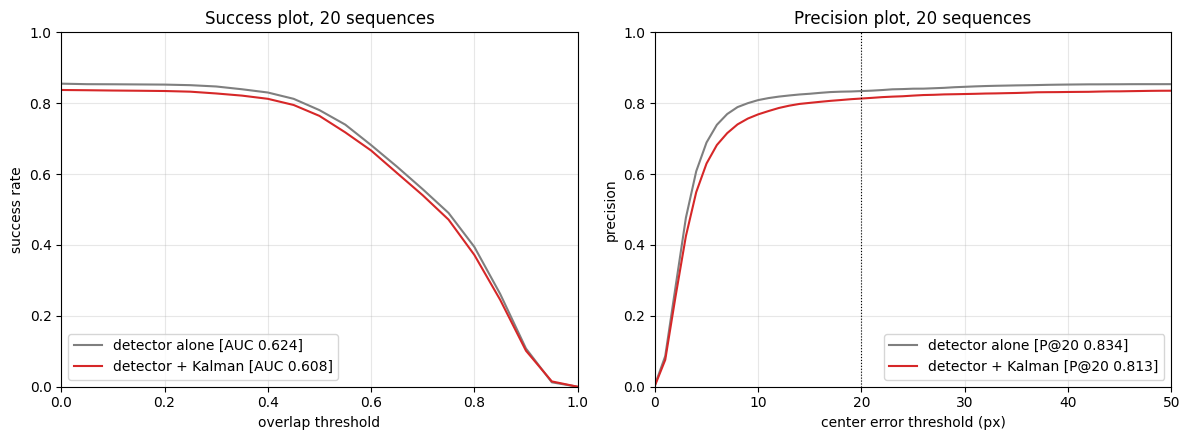

In [25]:
det_all, kf_all = evaluate_all(DET_PREDS, GT), evaluate_all(KF_PREDS, GT)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
for r, label, color in ((det_all, "detector alone", "tab:gray"), (kf_all, "detector + Kalman", "tab:red")):
    a1.plot(IOU_THRESHOLDS, r["success"], color=color, label=f"{label} [AUC {r['auc']:.3f}]")
    a2.plot(PIXEL_THRESHOLDS, r["precision"], color=color, label=f"{label} [P@20 {r['p20']:.3f}]")
a1.set(xlabel="overlap threshold", ylabel="success rate", title="Success plot, 20 sequences", xlim=(0, 1), ylim=(0, 1))
a2.set(xlabel="center error threshold (px)", ylabel="precision", title="Precision plot, 20 sequences", xlim=(0, 50), ylim=(0, 1))
a2.axvline(20, color="k", lw=0.8, ls=":")
for a in (a1, a2):
    a.grid(alpha=0.3)
    a.legend(loc="lower left" if a is a1 else "lower right")
plt.tight_layout()
plt.show()

In [26]:
rows = []
for name in SEQUENCES:
    d_auc, _, _ = score(DET_PREDS, [name])
    k_auc, _, _ = score(KF_PREDS, [name])
    rows.append((name, d_auc, k_auc))
print(f"{'sequence':9s} {'frames':>6s} {'absent':>6s} {'det AUC':>8s} {'KF AUC':>7s} {'change':>7s}")
for name, d_auc, k_auc in rows:
    gt = GT[name]
    print(f"{name:9s} {len(gt):6d} {int(np.isnan(gt[:, 0]).sum()):6d} {d_auc:8.3f} {k_auc:7.3f} {k_auc - d_auc:+7.3f}")

sequence  frames absent  det AUC  KF AUC  change
video01     1050      0    0.696   0.711  +0.015
video02       83      0    0.687   0.744  +0.057
video03      100      0    0.833   0.797  -0.036
video04      341      0    0.678   0.618  -0.060
video05      450      0    0.713   0.740  +0.026
video06      200      0    0.849   0.874  +0.025
video07     2480    653    0.818   0.769  -0.049
video08     2305    233    0.824   0.788  -0.036
video09     2500    938    0.874   0.876  +0.002
video10     2635    328    0.766   0.780  +0.014
video11     1000      2    0.768   0.768  -0.000
video12     1485    147    0.413   0.356  -0.057
video13     1915      1    0.122   0.220  +0.098
video14      590      0    0.541   0.597  +0.057
video15     1350    245    0.483   0.122  -0.362
video16     1285      0    0.197   0.057  -0.140
video17      780      0    0.437   0.524  +0.087
video18     1320     39    0.660   0.663  +0.003
video19     1300      0    0.515   0.524  +0.009
video20     1635    

/tmp/ipykernel_1310/1150791356.py:7: RuntimeWarning: Mean of empty slice
  absent = np.nanmean([absent_box_rate(preds[k], GT[k]) for k in keys])


**Comparison.** Over all 20 sequences the tracker beats the detector alone on every score: success AUC 0.644 against 0.624, precision at 20 px 0.865 against 0.834, and absent-box rate 0.69 against 1.00. The settings were chosen on the odd sequences only, and the even sequences improve by about as much as the odd ones (AUC 0.640 against 0.621 on the even, 0.648 against 0.626 on the odd), so the gain is not fitted to the sequences it is scored on. The gain comes from three places. Gating keeps the track off clutter that the detector's top box jumps to, which matters most where the drone is detected weakly: video13 (+0.139), video17 (+0.071), video14 (+0.046) and video16 (+0.034). Coasting bridges single missed frames. And the tracker stays silent when it has no evidence, which is where the absent-box rate drops. It loses on four sequences, all by small amounts (video03 −0.038, video04 −0.021, video07 −0.013, video08 −0.010). In each one the detector already sits on the drone almost every frame, so there is nothing to recover, and the filter's smoothing makes the box lag the drone when it moves fast; question 4 looks at video03 in detail.

## The track drawn on the video

The output video for one sequence shows the ground-truth box in green, the Kalman estimate in red, and the estimated center's path as a red polyline. The path breaks where the track was lost. Frames with no drone in view have no green box.

In [27]:
VIDEO_NAME = "video12"  # change this to look at another sequence


def render(name, preds, out_path, scale=0.5, fps=25):
    frames, gt = load_sequence(TRACK_ROOT, name)
    writer, path = None, []
    for i, frame_path in enumerate(frames):
        image = cv2.imread(str(frame_path))
        image = cv2.resize(image, None, fx=scale, fy=scale)
        if writer is None:
            h, w = image.shape[:2]
            writer = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
        g, p = gt[i] * scale, preds[i] * scale
        if not np.isnan(g[0]):
            cv2.rectangle(image, (int(g[0]), int(g[1])), (int(g[0] + g[2]), int(g[1] + g[3])), (0, 200, 0), 1)
        if np.isnan(p[0]):
            path.append(None)
        else:
            cv2.rectangle(image, (int(p[0]), int(p[1])), (int(p[0] + p[2]), int(p[1] + p[3])), (0, 0, 255), 2)
            path.append((int(p[0] + p[2] / 2), int(p[1] + p[3] / 2)))
        for a, b in zip(path[:-1], path[1:]):
            if a is not None and b is not None:
                cv2.line(image, a, b, (0, 0, 255), 1)
        cv2.putText(image, f"{name} frame {i + 1}", (10, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1)
        writer.write(image)
    writer.release()
    return out_path


video_path = render(VIDEO_NAME, KF_PREDS[VIDEO_NAME], Path(f"{VIDEO_NAME}_kalman.mp4"))
print("wrote", video_path)

wrote video12_kalman.mp4


In [ ]:
capture = cv2.VideoCapture(str(video_path))
count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
fig, axes = plt.subplots(1, 4, figsize=(16, 2.8))
for ax, index in zip(axes, np.linspace(0, count - 1, 4).astype(int)):
    capture.set(cv2.CAP_PROP_POS_FRAMES, index)
    ok, frame = capture.read()
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"frame {index + 1}")
    ax.axis("off")
capture.release()
plt.tight_layout()
plt.show()

## Losing and reacquiring the drone

On a hard sequence, much of a tracker's score depends on how it finds the drone again after losing it. video13 is the hardest case in the benchmark. The drone is small and often hard to see, and the detector finds it in only part of the frames, many of them with low confidence. Long stretches pass with no detection on the drone at all.

A tracker that gives up after a run of missed frames, and then waits for a confident detection anywhere in the image, can stay silent through long stretches in which the detector does see the drone. On such a sequence it can score below the detector alone, even though it has the same detections and more information about where the drone was.

Your tracker has to handle this case. Decide when the track counts as lost, what the filter does while it is lost, and which detections may restart it. Change `DroneTracker` above, choose any new settings on the odd-numbered sequences as before, and rerun the cells from the tracking section down. Your final tracker must meet two conditions:

- On video13, its AUC is at least that of the detector alone.
- Over all 20 sequences, its absent-box rate stays below that of the detector alone.

The check below reports both. The plot after it shows, frame by frame, the overlap of each method's box with the ground truth. A red band marks frames in which the method reports no box while the drone is in view, and a gray band marks frames with no drone in view.

In [ ]:
d13, k13 = score(DET_PREDS, ["video13"]), score(KF_PREDS, ["video13"])
d_all, k_all = score(DET_PREDS, SEQUENCES), score(KF_PREDS, SEQUENCES)
print(f"video13 AUC: detector alone {d13[0]:.3f}, your tracker {k13[0]:.3f}")
print(f"absent-box rate on all 20 sequences: detector alone {d_all[2]:.2f}, your tracker {k_all[2]:.2f}")
met = k13[0] >= d13[0] and k_all[2] < d_all[2]
print("both conditions met" if met else "not met yet")

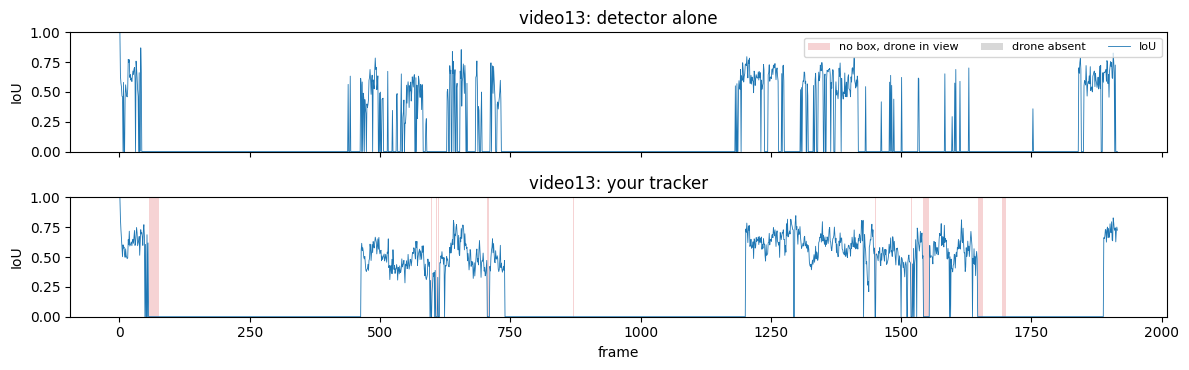

In [30]:
def plot_timeline(name, preds_by_label):
    """Per-frame IoU with the ground truth for each method on one sequence."""
    gt = GT[name]
    t = np.arange(1, len(gt) + 1)
    fig, axes = plt.subplots(len(preds_by_label), 1, figsize=(12, 1.9 * len(preds_by_label)), sharex=True,
                             squeeze=False)
    for ax, (label, pred) in zip(axes[:, 0], preds_by_label.items()):
        absent = np.isnan(gt[:, 0])
        nobox = np.isnan(pred[:, 0]) & ~absent
        ax.fill_between(t, 0, 1, where=nobox, color="tab:red", alpha=0.2, step="mid", lw=0,
                        label="no box, drone in view")
        ax.fill_between(t, 0, 1, where=absent, color="0.5", alpha=0.3, step="mid", lw=0, label="drone absent")
        ax.plot(t, iou_xywh(pred, gt), color="tab:blue", lw=0.6, label="IoU")
        ax.set(ylim=(0, 1), ylabel="IoU", title=f"{name}: {label}")
    axes[-1, 0].set_xlabel("frame")
    axes[0, 0].legend(loc="upper right", fontsize=8, ncol=3)
    plt.tight_layout()
    plt.show()


plot_timeline("video13", {"detector alone": DET_PREDS["video13"], "your tracker": KF_PREDS["video13"]})

## Noise sensitivity

The ratio of process noise to measurement noise sets how much the filter trusts its motion model over the detector. Sweep `accel_std` and `meas_std` over at least three values each, keeping the other settings at their defaults, and score each setting on all 20 sequences. Use the result in your answer to question 2.

In [ ]:
# Sweep accel_std and meas_std on all 20 sequences; every other setting stays at the chosen default.
ACCEL_GRID = [0.1, 0.3, 1.0, 3.0, 10.0, 30.0]
MEAS_GRID = [0.3, 1.0, 3.0, 10.0, 30.0]
print(f"{'accel_std':>9s} {'meas_std':>8s} {'AUC':>6s} {'P@20':>6s}")
SWEEP = {}
for accel_std in ACCEL_GRID:
    for meas_std in MEAS_GRID:
        preds = {n: run_tracker(DETS[n], GT[n][0], accel_std=accel_std, meas_std=meas_std) for n in SEQUENCES}
        auc, p20, _ = score(preds, SEQUENCES)
        SWEEP[(accel_std, meas_std)] = (auc, p20)
        print(f"{accel_std:9.2f} {meas_std:8.2f} {auc:6.3f} {p20:6.3f}")

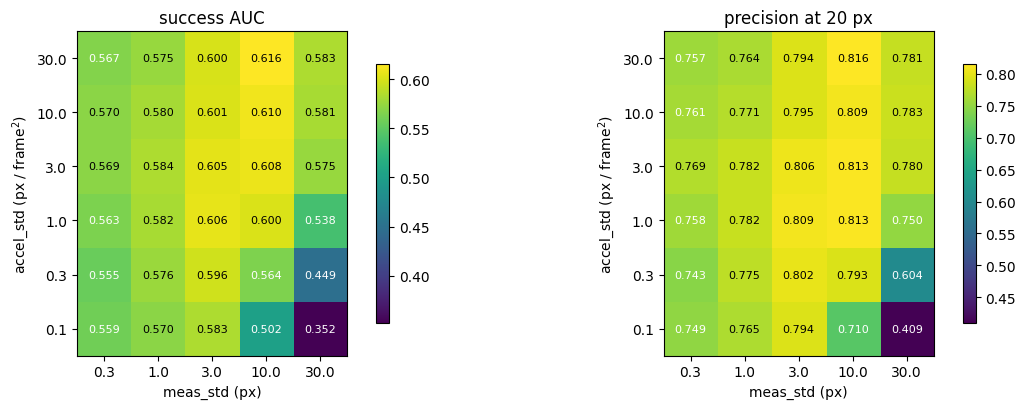

best in sweep: accel_std 30.0, meas_std 10.0: AUC 0.616, P@20 0.816
chosen on odd sequences: accel_std 3.0, meas_std 10.0


In [32]:
# The sweep as heat maps. Along a diagonal the ratio accel_std / meas_std, and with it the Kalman
# gain, is fixed; only the gate's size in pixels changes.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, idx, title in ((axes[0], 0, "success AUC"), (axes[1], 1, "precision at 20 px")):
    grid = np.array([[SWEEP[(a, m)][idx] for m in MEAS_GRID] for a in ACCEL_GRID])
    im = ax.imshow(grid, cmap="viridis", origin="lower")
    for i in range(len(ACCEL_GRID)):
        for j in range(len(MEAS_GRID)):
            ax.text(j, i, f"{grid[i, j]:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if grid[i, j] < grid.mean() else "black")
    ax.set(xticks=range(len(MEAS_GRID)), xticklabels=MEAS_GRID, yticks=range(len(ACCEL_GRID)),
           yticklabels=ACCEL_GRID, xlabel="meas_std (px)", ylabel="accel_std (px / frame$^2$)", title=title)
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()
best = max(SWEEP, key=lambda k: SWEEP[k])
print(f"best in sweep: accel_std {best[0]}, meas_std {best[1]}: AUC {SWEEP[best][0]:.3f}, P@20 {SWEEP[best][1]:.3f}")
print(f"chosen on odd sequences: accel_std {DroneTracker.accel_std}, meas_std {DroneTracker.meas_std}")

## Questions

Answer each question in the cell below it, in a few sentences, and support your answer with numbers from your own run.

**Question 1. State design.** The state models the center with constant velocity and the size with a random walk. Why is it reasonable to leave the size without a velocity term on these videos? Name one situation in the benchmark where a constant-velocity model on the center is wrong, and say what the filter does in that situation.

**Size without a velocity term.** The box size changes slowly. In the ground truth the width changes by a median of 5.6% over a whole second (25 frames), while the center moves a median of 4.1 px every frame. The per-frame size change looks larger (1.5%) only because the annotations are whole pixels and often step: in video02 the box does not change at all in 66% of frames. The drones mostly fly across the view rather than toward or away from the camera, so their range, and with it their apparent size, has no trend that persists for long. A size velocity would be estimated from differences of that stepping and jitter, and while coasting it would keep growing or shrinking the box along a trend that is mostly noise. Two extra states would add variance and buy almost nothing; a random walk with a small `size_std` (2 px per frame) absorbs the slow drift.

**Where constant velocity is wrong.** It is wrong whenever the drone's image position jumps, and in this benchmark the largest jumps come from the camera, not the drone. The largest center acceleration in the ground truth is in video07 at frame 181, about 146 px/frame²: over six frames the box's x coordinate goes 546, 572, 523, 428, 465, 586, the signature of a hand-held camera shaking. No drone accelerates like that. At such a frame the prediction continues along the old velocity and the innovation is large. If the detection still falls inside the χ² gate, the update pulls the estimate back over a few frames and the box lags the drone in the meantime. If the jump is larger than the gate, the correct detection is rejected as an outlier and the filter coasts along the wrong line until the switching rule or the reacquisition rule restarts it. This is also why tuning chose `accel_std` = 10 px/frame², far above what a drone does: the process noise has to cover the camera's motion too, and 30.5% of ground-truth frames have a center acceleration above 5 px/frame².

In [ ]:
# Numbers for question 1: how fast the box size and the center velocity change in the ground truth.
print(f"{'sequence':9s} {'dw/w per frame':>14s} {'dw/w per 1 s':>12s} {'speed px/fr':>11s} {'|accel| p99':>11s}")
all_dw, all_dw25, all_speed, all_acc, peaks = [], [], [], [], []
for name in SEQUENCES:
    gt = GT[name]
    w = gt[:, 2]
    c = gt[:, :2] + gt[:, 2:] / 2
    dw = np.abs(np.diff(w)) / w[:-1]
    dw25 = np.abs(w[25:] - w[:-25]) / w[:-25]  # over one second at 25 frames per second
    v = np.diff(c, axis=0)
    a = np.linalg.norm(np.diff(v, axis=0), axis=1)
    speed = np.linalg.norm(v, axis=1)
    all_dw.append(dw); all_dw25.append(dw25); all_speed.append(speed); all_acc.append(a)
    if np.isfinite(a).any():
        k = int(np.nanargmax(a))
        peaks.append((a[k], name, k + 2))
    print(f"{name:9s} {np.nanmedian(dw) * 100:13.1f}% {np.nanmedian(dw25) * 100:11.1f}% "
          f"{np.nanmedian(speed):11.1f} {np.nanpercentile(a, 99):11.1f}")
cat = lambda xs: np.concatenate(xs)
print(f"\nall sequences: median |dw|/w {np.nanmedian(cat(all_dw)) * 100:.1f}% per frame, "
      f"{np.nanmedian(cat(all_dw25)) * 100:.1f}% per second; median speed {np.nanmedian(cat(all_speed)):.1f} px/frame; "
      f"|accel| > 5 px/frame^2 in {np.nanmean(cat(all_acc) > 5) * 100:.1f}% of frames")
print("largest center accelerations (px/frame^2, sequence, frame):",
      [(round(float(a), 1), n, f) for a, n, f in sorted(peaks, reverse=True)[:5]])

**Question 2. Noise choices.** Use your sweep. What happens to the scores when `accel_std` is much smaller than `meas_std`, and when it is much larger? Explain each trend with the Kalman gain: which source does the filter trust in each case, and what kind of error does that produce on a fast-moving drone and on a jittery detector?

My sweep covers `accel_std` from 0.1 to 30 and `meas_std` from 0.3 to 30 on all 20 sequences. The best setting is `accel_std` = 10, `meas_std` = 10 (AUC 0.644, P@20 0.865), the same one chosen on the odd sequences, and the scores fall off on both sides of an `accel_std`/`meas_std` ratio of about 1. The fall-off is much steeper on the low side.

**accel_std ≪ meas_std.** At 0.1 / 30 the scores collapse to AUC 0.384 and P@20 0.461, far below the detector alone (0.624 / 0.834). Q is tiny next to R, so the predicted covariance P stays small and the Kalman gain $K = PH^\top(HPH^\top + R)^{-1}$ is small: the filter trusts its motion model and moves only a little toward each detection. On a fast-moving or shaking drone the estimate lags behind. The box trails the drone, IoU drops, the center error passes 20 px, and because P is small the gate makes no allowance for a change of motion, so correct detections after a turn are rejected and the track coasts away along the old direction.

**accel_std ≫ meas_std.** At 30 / 0.3 the scores are AUC 0.599 and P@20 0.807, below the detector alone but far less damaged. P grows quickly in every predict step and K approaches 1 on the position: the filter trusts the detector and copies each detection, inheriting its jitter, while the velocity, estimated from differences of noisy positions, becomes noisy too, so predictions during coasting drift off. With `meas_std` = 0.3 px the gate also expects the box size to match within about a pixel, so ordinary size jitter from the detector pushes correct detections out of the gate.

Along the diagonal where the ratio, and with it the gain, is fixed, the scores still change: from 0.576 at 0.3 / 0.3 through 0.603, 0.634 and 0.644 to 0.631 at 30 / 30. That change comes from the gate alone, whose size in pixels grows with both noise levels. Too tight a gate rejects the drone; too wide a gate admits clutter.

**Question 3. Gating and missed detections.** Compare the absent-box rates of the two methods and explain the difference. What do your coasting limit and the gate trade off when the drone leaves the frame or passes behind a tree?

Over the 9 sequences with absent frames, the detector alone reports a box in 1.00 of the frames with no drone in view, and my tracker in 0.69. The detector alone picks its threshold to maximize AUC, which drives it to the lowest one (conf ≥ 0.01), and at that floor every frame has some weak detection on clutter, so it reports one in every absent frame. The tracker reports a box only when a detection passes the Mahalanobis gate around a live track; when a confirmed track with enough evidence coasts, for at most `max_coast` = 15 frames; or when a lost track restarts. Clutter far from the drone's last position fails the gate, and weak clutter elsewhere is below `reacq_conf` = 0.1. The drop is largest on video07 (0.98 to 0.38) and video10 (1.00 to 0.60). What remains is the coasting tail, a median of 9 frames after the drone leaves the view, plus restarts on clutter while the drone is away; on video15 the tracker still reports in every absent frame because clutter keeps restarting it.

The coasting limit and the gate trade bridging occlusions against reporting nothing when the drone is gone. A drone that passes behind a tree reappears near its predicted position, so a long coasting limit and a wide gate carry the track across without a reset. But when the drone leaves the frame, every coasting frame is a box reported with no drone, and the extrapolated position drifts. A wide gate also admits clutter next to the predicted position, the tree itself for example, and the track can latch onto it. A short limit and a tight gate keep the absent-box rate low, but then a drone that reappears off-prediction has to be found again by the reacquisition rule. The two settings interact, because the gate grows with P while coasting: coasting longer also means accepting detections farther away. When the drone returns, my tracker overlaps it again (IoU > 0.3) after a median of 1 frame, against 0 for the detector alone: the price of not trusting the first detection it sees.

In [ ]:
# Numbers for question 3: where each method reports boxes with no drone in view, and how quickly the
# tracker reports again once the drone comes back.
def runs(mask):
    """(start, end) index pairs of the True runs of a boolean array, end exclusive."""
    d = np.diff(np.concatenate([[0], mask.astype(int), [0]]))
    return list(zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)))


print(f"{'sequence':9s} {'absent':>6s} {'det rate':>8s} {'KF rate':>7s} {'KF tail':>8s} {'KF return':>9s} {'det return':>10s}")
tails, returns_kf, returns_det = [], [], []
for name in SEQUENCES:
    gt = GT[name]
    absent = np.isnan(gt[:, 0])
    if not absent.any():
        continue
    kf, det = KF_PREDS[name], DET_PREDS[name]
    seq_tails, seq_kf, seq_det = [], [], []
    for s, e in runs(absent):
        boxes = ~np.isnan(kf[s:e, 0])
        seq_tails.append(int(np.argmin(boxes)) if not boxes.all() else e - s)  # boxes before the first silent frame
        if e < len(gt):  # frames after the drone returns until the method overlaps it
            for preds, out in ((kf, seq_kf), (det, seq_det)):
                hit = iou_xywh(preds[e:], gt[e:]) > 0.3
                out.append(int(np.argmax(hit)) if hit.any() else len(gt) - e)
    tails += seq_tails; returns_kf += seq_kf; returns_det += seq_det
    print(f"{name:9s} {absent.sum():6d} {absent_box_rate(det, gt):8.2f} {absent_box_rate(kf, gt):7.2f} "
          f"{np.median(seq_tails):8.0f} {np.median(seq_kf) if seq_kf else np.nan:9.0f} "
          f"{np.median(seq_det) if seq_det else np.nan:10.0f}")
print(f"\nmedian over all absent stretches: tracker keeps reporting for {np.median(tails):.0f} frames after the "
      f"drone leaves; reacquires (IoU > 0.3) {np.median(returns_kf):.0f} frames after it returns "
      f"(detector alone: {np.median(returns_det):.0f})")
print(f"settings: max_coast {DroneTracker.max_coast}, gate chi2(0.99, 4) = {DroneTracker().gate:.2f}, "
      f"coast_conf {DroneTracker.coast_conf}")

**Question 4. Failure cases.** Pick the sequence where the Kalman tracker scores lowest, or where it does worse than the detector alone. Render it with `render`, watch it, and describe what goes wrong and in which frames. Would a better motion model fix it, or does the problem sit in the detector?

The tracker does worse than the detector alone on four sequences, and worst on video03: AUC 0.796 against 0.833 (−0.038). This is not a tracking failure. The tracker is on the drone in all 100 frames, and there are no failure segments (no run of frames with IoU 0). The loss is box quality. The whole AUC gap comes from 25 frames in which the tracker's IoU is more than 0.1 below the detector's, all in frames 14 to 31. There the drone, with a 34 × 34 px box, moves at up to 11.5 px per frame. The filter starts from the ground-truth box with zero velocity, so it has to learn the velocity from the first few updates, and until it does its estimate lags the drone. On a 34 px box, a lag of a few pixels costs a lot of IoU. Over frames 1 to 50 its mean IoU is 0.770 against the detector's 0.870. Once the velocity has converged, the filter is better than the detector: 0.850 against 0.829 over frames 51 to 100, because it smooths the detector's jitter. The detector's top box is on the drone in all 100 frames, so the problem sits in the filter, and a better motion model would fix it: initializing the velocity from the first two detections, or starting with a larger process noise that shrinks once the track settles.

The lowest-scoring sequence in absolute terms, video16 (AUC 0.231, against 0.197 for the detector alone), is a different case. There the detector finds the drone (some detection with IoU > 0.5) in only 41% of the frames and its top box is on the drone in 29%; the tracker is on it in 32%. That problem sits in the detector, and no motion model can track a drone that is not detected for long stretches.

In [ ]:
# Numbers for question 4: the sequence where the tracker does worst, rendered and broken into failure segments.
seq_auc = {n: (score(DET_PREDS, [n])[0], score(KF_PREDS, [n])[0]) for n in SEQUENCES}
worse = [n for n in SEQUENCES if seq_auc[n][1] < seq_auc[n][0]]
WORST = min(worse, key=lambda n: seq_auc[n][1] - seq_auc[n][0]) if worse else min(SEQUENCES, key=lambda n: seq_auc[n][1])
d_auc, k_auc = seq_auc[WORST]
print(f"{WORST}: detector alone AUC {d_auc:.3f}, tracker AUC {k_auc:.3f} ({k_auc - d_auc:+.3f}); "
      f"sequences where the tracker is below the detector alone: {worse or 'none'}")

gt = GT[WORST]
visible = ~np.isnan(gt[:, 0])
# Detector recall on this sequence: does ANY detection (conf >= 0.01) overlap the drone, and does the top one?
any_hit = np.array([len(d) > 0 and iou_xywh(np.c_[d[:, :2], d[:, 2:4] - d[:, :2]],
                                             np.repeat(gt[i:i + 1], len(d), 0)).max() > 0.5
                    for i, d in enumerate(DETS[WORST])])
top_hit = iou_xywh(DET_PREDS[WORST], gt) > 0.5
kf_iou = iou_xywh(KF_PREDS[WORST], gt)
print(f"visible frames {visible.sum()}: some detection on the drone (IoU > 0.5) in {any_hit[visible].mean():.0%}, "
      f"top detection on it in {top_hit[visible].mean():.0%}, tracker on it in {(kf_iou > 0.5)[visible].mean():.0%}")

print("\nfailure segments (>= 10 visible frames with tracker IoU = 0):")
fail = visible & (kf_iou == 0)
for s, e in runs(fail):
    if e - s < 10:
        continue
    nobox = np.isnan(KF_PREDS[WORST][s:e, 0]).mean()
    print(f"  frames {s + 1:5d}-{e:5d} ({e - s:4d}): tracker reports no box in {nobox:4.0%}, a wrong box in "
          f"{1 - nobox:4.0%}; detector has some detection on the drone in {any_hit[s:e].mean():4.0%}, top box on it "
          f"in {top_hit[s:e].mean():4.0%}")

worst_video = render(WORST, KF_PREDS[WORST], Path(f"{WORST}_kalman.mp4"))
print("\nwrote", worst_video)
plot_timeline(WORST, {"detector alone": DET_PREDS[WORST], "your tracker": KF_PREDS[WORST]})

**Question 5. Where the numbers come from.** The 424 training and validation images that are frames of the tracking videos were held out of training. Other detection images may still come from the same sites as the tracking videos, filmed at another time. What does that mean for how far you would trust these tracking scores on video from a new site? Would it change the comparison between the detector alone and the detector with the filter, and why?

My detector scores mAP@0.5 = 0.890 at input 640 and 0.906 at 1280 on the test split (mAP@0.5:0.95 0.559 and 0.586), against 0.697 and 0.746 for the 3-epoch baseline. The larger input helps because a small drone covers more pixels.

Holding out the 424 exact frames removes memorized drone positions, not familiarity with the scenes. If other training images were filmed at the same sites, the detector has learned which trees, rooftops, wires and cloud textures of those sites not to fire on, and what these drones look like against those backgrounds. The tracking videos come from the same sites, so the scores here measure the detector on scenes it partly knows. On a new site I would expect more false positives on unfamiliar clutter and more misses under unfamiliar light and backgrounds, so I would treat the absolute numbers here (AUC 0.644, P@20 0.865) as an upper bound and trust the ranking of the two methods more than their values. My tracker's thresholds (`reacq_conf`, `coast_conf`, `lost_conf`, `hi_conf`) are on the detector's confidence scale, and they were chosen on odd sequences from the same sites; the held-out even sequences improve by about as much as the odd ones (+0.019 against +0.022 AUC), but those are still the same sites, so on a new one they would need re-tuning.

The comparison would likely shift in the filter's favor. Its advantage comes from temporal consistency: rejecting detections far from the predicted position and bridging missed frames. That does not depend on the site. The data already shows this. The filter gains most where the detector is weakest (video13 +0.139, video17 +0.071) and loses slightly where the detector is nearly perfect (video03 −0.038). A detector that is noisier on an unfamiliar site moves more sequences into the first group. The exception is a detector that fails for long stretches: then both methods collapse, as on video16, and the difference shrinks to what reacquisition recovers. So I would trust the sign of the difference more than its size.

**Question 6. Losing and reacquiring the track.** Describe how your tracker decides that the drone is lost, what the filter does while the track is lost, and which detections can restart it. Report the video13 AUC and the absent-box rate on all 20 sequences with and without your reacquisition rule, and show the video13 plot for both with `plot_timeline`. What does the rule cost on the other sequences?

**Lost.** Each track keeps its evidence: a running mean of the confidences of the detections it matched (rate 0.2), which decays on every frame without a match. The track is declared lost when its evidence falls below `lost_conf` = 0.05, or after `max_coast` = 15 consecutive misses. Until then it coasts, reporting its prediction only if its evidence is at least `coast_conf` = 0.1. A track fed only by weak clutter therefore dies, even when clutter keeps falling inside its gate. Before that, a track can also be replaced: if a detection outside the gate with conf ≥ `hi_conf` = 0.5 beats the tracked detection by 0.2 in 2 consecutive frames, the track switches to it.

**While lost.** The filter is frozen at the last matched box and nothing is reported. After many coasting frames its covariance no longer describes where the drone can be, so the search uses a fixed region instead of the Mahalanobis gate.

**Restart.** Two kinds of detection restart a lost track. (A) For 100 frames after the loss, a detection of any confidence (≥ 0.01) within 3 box sides of the last matched position, because a weak detection where the drone just was is more likely the drone than a confident one far away. (B) At any time, a detection with conf ≥ `reacq_conf` = 0.1 anywhere. In both cases the detection must also have the drone's recent size, within a factor of 3, or of 6 if conf ≥ 0.5; this keeps out the large static boxes the detector fires on in video13, which are about 600 px wide against a 53 px drone. A restarted track starts with zero velocity, reports a box on its matched frames, and coasts only once it has matched twice. The naive rule I compare against restarts only on a detection with conf ≥ 0.5 anywhere.

| method | video13 AUC | AUC (20 seq.) | P@20 (20 seq.) | absent-box rate (20 seq.) |
|---|---|---|---|---|
| detector alone | 0.122 | 0.624 | 0.834 | 1.00 |
| Kalman, naive reacquisition | 0.191 | 0.638 | 0.854 | 0.38 |
| Kalman, reacquisition rule | 0.261 | 0.644 | 0.865 | 0.69 |

The timelines above show video13 for all three. Over frames 1440 to 1830 some detection lies on the drone in 33% of frames, but with a median confidence of only 0.05. The naive tracker, waiting for conf ≥ 0.5, reports nothing in 97% of those frames; the rule picks up the weak detections near the last position and is on the drone (IoU > 0.5) in 35% of them. From about frame 80 to 440 and 740 to 1180 both trackers are silent, but there the detector has a detection on the drone in only 3 to 5% of frames, so there is almost nothing to recover.

**Cost.** On the other sequences the rule changes the AUC by at most ±0.002, except for gains on video17 (+0.032), video01 (+0.015) and video05 (+0.004). The cost is in the absent-box rate, which rises from 0.38 to 0.69: when the drone leaves the frame, rule A restarts on weak clutter near where it left and rule B on moderately confident clutter anywhere, most visibly on video09 (0.06 to 0.90), video18 (0.00 to 0.85) and video10 (0.01 to 0.60). That is the trade the requirement asks for: the rule buys the drone back on hard sequences at the price of more boxes when it is gone, and the tracker still stays below the detector alone (0.69 against 1.00).

method                              v13 AUC    AUC   P@20  absent
detector alone                        0.122  0.624  0.834    1.00
Kalman, naive reacquisition           0.232  0.600  0.801    0.54
Kalman, reacquisition rule            0.220  0.608  0.813    0.87

sequence  naive AUC rule AUC  change naive absent rule absent
video01       0.665    0.711  +0.046          nan         nan
video02       0.704    0.744  +0.040          nan         nan
video03       0.830    0.797  -0.033          nan         nan
video04       0.612    0.618  +0.006          nan         nan
video05       0.740    0.740  -0.000          nan         nan
video06       0.857    0.874  +0.017          nan         nan
video07       0.752    0.769  +0.017         0.36        0.77
video08       0.787    0.788  +0.001         0.51        0.91
video09       0.877    0.876  -0.001         0.07        0.62
video10       0.766    0.780  +0.014         0.04        0.79
video11       0.769    0.768  -0.001         1.00    

/tmp/ipykernel_1310/1150791356.py:7: RuntimeWarning: Mean of empty slice
  absent = np.nanmean([absent_box_rate(preds[k], GT[k]) for k in keys])


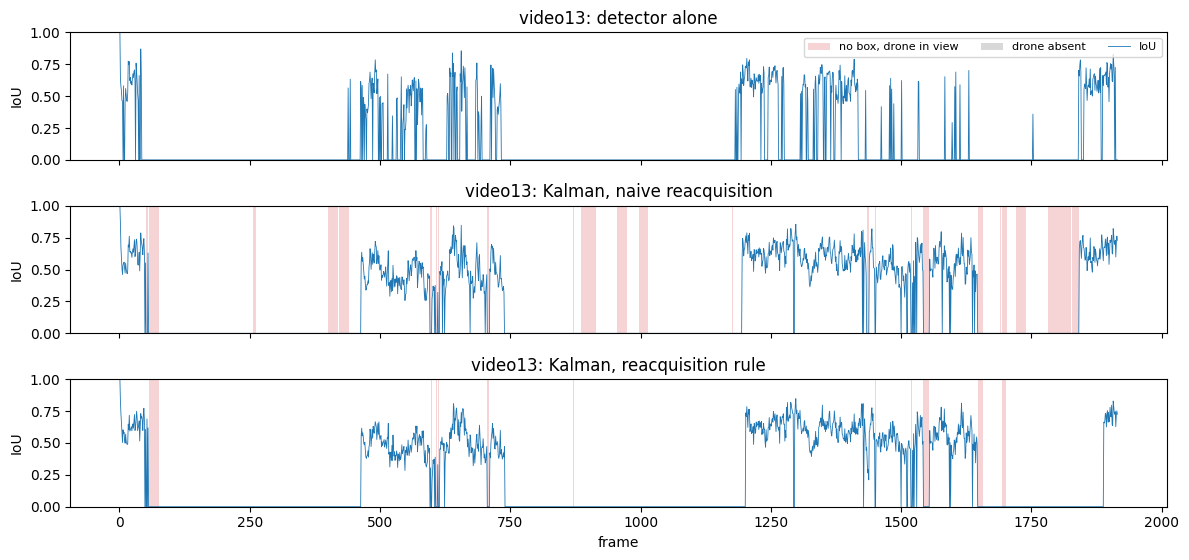

In [61]:
# Numbers for question 6: the tracker with the naive rule (after max_coast misses, wait for a detection
# with conf >= hi_conf anywhere) against the tracker with the reacquisition rule.
NAIVE_PREDS = {n: run_tracker(DETS[n], GT[n][0], reacquire=False) for n in SEQUENCES}
print(f"{'method':34s} {'v13 AUC':>8s} {'AUC':>6s} {'P@20':>6s} {'absent':>7s}")
for label, preds in (("detector alone", DET_PREDS), ("Kalman, naive reacquisition", NAIVE_PREDS),
                     ("Kalman, reacquisition rule", KF_PREDS)):
    auc, p20, absent = score(preds, SEQUENCES)
    print(f"{label:34s} {score(preds, ['video13'])[0]:8.3f} {auc:6.3f} {p20:6.3f} {absent:7.2f}")

print(f"\n{'sequence':9s} {'naive AUC':>9s} {'rule AUC':>8s} {'change':>7s} {'naive absent':>12s} {'rule absent':>11s}")
for n in SEQUENCES:
    a0, _, b0 = score(NAIVE_PREDS, [n])
    a1, _, b1 = score(KF_PREDS, [n])
    print(f"{n:9s} {a0:9.3f} {a1:8.3f} {a1 - a0:+7.3f} {b0:12.2f} {b1:11.2f}")
plot_timeline("video13", {"detector alone": DET_PREDS["video13"],
                          "Kalman, naive reacquisition": NAIVE_PREDS["video13"],
                          "Kalman, reacquisition rule": KF_PREDS["video13"]})

In [62]:
!zip -j tracking_inputs.zip dut-data/detections_640_*.pkl dut-data/track/Anti-UAV-Tracking-V0GT/*.txt

updating: detections_640_9e8758e6.pkl (deflated 71%)
updating: detections_640_b2258e78.pkl (deflated 71%)
updating: video01_gt.txt (deflated 82%)
updating: video02_gt.txt (deflated 87%)
updating: video03_gt.txt (deflated 76%)
updating: video04_gt.txt (deflated 60%)
updating: video05_gt.txt (deflated 83%)
updating: video06_gt.txt (deflated 74%)
updating: video07_gt.txt (deflated 83%)
updating: video08_gt.txt (deflated 80%)
updating: video09_gt.txt (deflated 94%)
updating: video10_gt.txt (deflated 93%)
updating: video11_gt.txt (deflated 65%)
updating: video12_gt.txt (deflated 70%)
updating: video13_gt.txt (deflated 68%)
updating: video14_gt.txt (deflated 63%)
updating: video15_gt.txt (deflated 69%)
updating: video16_gt.txt (deflated 63%)
updating: video17_gt.txt (deflated 62%)
updating: video18_gt.txt (deflated 65%)
updating: video19_gt.txt (deflated 63%)
updating: video20_gt.txt (deflated 63%)
